# Module 3: Fracture Position Detection — YOLO26


**Pipeline stages:**
1. Install dependencies
2. Download all 3 datasets via Roboflow
3. Imports & configuration
4. Create merged dataset structure
5. Copy & merge all datasets
6. Dataset summary
7. Write `data.yaml`
8. Train YOLO26
9. Evaluate on test set
10. Inference & visualize bounding boxes
11. Batch inference
12. Export model

---
## Cell 1 — Install Dependencies

In [1]:
!pip install -U ultralytics roboflow pyyaml matplotlib opencv-python-headless Pillow kaggle torch torchvision torchaudio

  Using cached ultralytics-8.4.41-py3-none-any.whl.metadata (39 kB)
  Using cached roboflow-1.3.5-py3-none-any.whl.metadata (11 kB)
  Using cached matplotlib-3.10.9-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (52 kB)
  Using cached opencv_python_headless-4.13.0.92-cp37-abi3-manylinux_2_28_x86_64.whl.metadata (19 kB)
  Using cached pillow-12.2.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (8.8 kB)
  Using cached kaggle-2.1.0-py3-none-any.whl.metadata (16 kB)
  Using cached opencv_python-4.13.0.92-cp37-abi3-manylinux_2_28_x86_64.whl.metadata (19 kB)
  Using cached scipy-1.17.1-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (62 kB)
  Using cached polars-1.40.1-py3-none-any.whl.metadata (10 kB)
  Using cached ultralytics_thop-2.0.19-py3-none-any.whl.metadata (14 kB)
  Using cached idna-3.7-py3-none-any.whl.metadata (9.9 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.0-c

In [1]:
import torch
print(torch.__version__)
print("CUDA available:", torch.cuda.is_available())
import gc
import torch
gc.collect()
if torch.cuda.is_available():
    dev = torch.cuda.get_device_properties(0)
    torch.cuda.empty_cache()
    print(f"GPU: {dev.name}")
    print(f"VRAM: {dev.total_memory / 1024**3:.1f} GB")

2.11.0+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 5090
VRAM: 31.4 GB


## Use Existing Merged Dataset

In [2]:
from pathlib import Path

merged_path = Path(MERGED_DIR) if "MERGED_DIR" in globals() else Path.cwd() / "Merged_Fracture"
print("Using merged-only workflow.")
print(f"MERGED_DIR candidate: {merged_path}")

Using merged-only workflow.
MERGED_DIR candidate: /workspace/Merged_Fracture


## Cell 3 — Imports & Configuration

> **Only `MERGED_DIR` and `PROJECT_DIR` need editing here**

In [3]:
import os
import csv
from pathlib import Path
import random
import shutil
import yaml

import cv2
import numpy as np
import matplotlib.patches as patches
import matplotlib.pyplot as plt
from ultralytics import YOLO

# Output configuration
WORKSPACE_DIR = Path.cwd()
MERGED_DIR = str(WORKSPACE_DIR / "Merged_Fracture")
PROJECT_DIR = str(WORKSPACE_DIR / "runs" / "detect")
RUN_NAME = "fracture_yolo26"
CONF_THRESHOLD = 0.25

# Profiles
CRASH_RECOVERY_MODE = False   # keep False for normal runs
RAM_SAFE_MODE = False
FAST_MODE = True
FULL_UTILIZATION_MODE = True  # cloud machine: high utilization without crashing

# Hardware-aware limits
CPU_COUNT = os.cpu_count() or 8
WORKER_CAP = 48  # avoid oversubscription/instability from very high worker counts

# Base settings
DEVICE = 0
USE_AMP = True
USE_MULTI_SCALE = False  # keep False to avoid resize-to-zero crash path
PATIENCE = 12

# CUDA allocator: helps reduce fragmentation at high memory usage
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

# Profile selection
if CRASH_RECOVERY_MODE:
    TRAIN_IMGSZ = 1024
    INFER_IMGSZ = 1024
    BATCH_SIZE = 8            # fixed batch avoids aggressive AutoBatch probing
    NUM_WORKERS = min(16, max(4, CPU_COUNT // 4))
    CACHE_MODE = "disk"       # avoids large RAM spikes from full RAM caching
    EPOCHS = 30
    PLOTS = False
    MOSAIC = 0.1
    CLOSE_MOSAIC = 2
    DEGREES = 5
elif FULL_UTILIZATION_MODE:
    TRAIN_IMGSZ = 1024
    INFER_IMGSZ = 1024
    BATCH_SIZE = 64           # high GPU usage with better stability than aggressive AutoBatch
    NUM_WORKERS = 8
    CACHE_MODE = "ram"       # stable on 64 GB RAM for this dataset size
    EPOCHS = 140
    PLOTS = True
    MOSAIC = 0.6
    CLOSE_MOSAIC = 15
    DEGREES = 10

elif FAST_MODE:
    TRAIN_IMGSZ = 1024
    INFER_IMGSZ = 1024
    BATCH_SIZE = 8
    NUM_WORKERS = min(32, max(8, CPU_COUNT // 3))
    CACHE_MODE = "ram"
    EPOCHS = 30
    PLOTS = False
    MOSAIC = 0.2
    CLOSE_MOSAIC = 2
    DEGREES = 5
else:
    TRAIN_IMGSZ = 1280
    INFER_IMGSZ = 1280
    BATCH_SIZE = 4
    NUM_WORKERS = min(24, max(4, CPU_COUNT // 4))
    CACHE_MODE = "disk"
    EPOCHS = 40
    PLOTS = True
    MOSAIC = 0.5
    CLOSE_MOSAIC = 5
    DEGREES = 10

if RAM_SAFE_MODE and CACHE_MODE == "ram":
    NUM_WORKERS = min(NUM_WORKERS, 24)

NUM_WORKERS = max(2, int(NUM_WORKERS))

Path(MERGED_DIR).mkdir(parents=True, exist_ok=True)
Path(PROJECT_DIR).mkdir(parents=True, exist_ok=True)

random.seed(42)
print("Configuration loaded.")
print(f"Merged dataset -> {MERGED_DIR}")
print(f"Training output -> {PROJECT_DIR}/{RUN_NAME}")
print("Training profile:")
print(f"  CRASH_RECOVERY_MODE={CRASH_RECOVERY_MODE}, FULL_UTILIZATION_MODE={FULL_UTILIZATION_MODE}, FAST_MODE={FAST_MODE}")
print(f"  TRAIN_IMGSZ={TRAIN_IMGSZ}, INFER_IMGSZ={INFER_IMGSZ}, BATCH_SIZE={BATCH_SIZE}")
print(f"  DEVICE={DEVICE}, NUM_WORKERS={NUM_WORKERS}, CACHE_MODE={CACHE_MODE}, AMP={USE_AMP}")
print(f"  CPU_COUNT={CPU_COUNT}, WORKER_CAP={WORKER_CAP}, MULTI_SCALE={USE_MULTI_SCALE}")
print(f"  EPOCHS={EPOCHS}, PLOTS={PLOTS}")
print(f"  PYTORCH_CUDA_ALLOC_CONF={os.environ.get('PYTORCH_CUDA_ALLOC_CONF')}")
if FULL_UTILIZATION_MODE:
    print("Cloud stable-max mode: fixed high batch + tuned workers + disk cache.")
    print("If GPU usage is low, increase BATCH_SIZE to 14.")

Configuration loaded.
Merged dataset -> /workspace/Merged_Fracture
Training output -> /workspace/runs/detect/fracture_yolo26
Training profile:
  CRASH_RECOVERY_MODE=False, FULL_UTILIZATION_MODE=True, FAST_MODE=True
  TRAIN_IMGSZ=1024, INFER_IMGSZ=1024, BATCH_SIZE=64
  DEVICE=0, NUM_WORKERS=8, CACHE_MODE=ram, AMP=True
  CPU_COUNT=192, WORKER_CAP=48, MULTI_SCALE=False
  EPOCHS=140, PLOTS=True
  PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True
Cloud stable-max mode: fixed high batch + tuned workers + disk cache.
If GPU usage is low, increase BATCH_SIZE to 14.


In [4]:
import os
import random
import shutil
from pathlib import Path

def balance_dataset(dataset_dir="/workspace/Merged_Fracture", split="train", keep_bg_count=500):
    images_dir = Path(dataset_dir) / split / "images"
    labels_dir = Path(dataset_dir) / split / "labels"
    
    # Create a backup folder for the excess backgrounds
    backup_img_dir = Path(dataset_dir) / f"{split}_excess_bg" / "images"
    backup_lbl_dir = Path(dataset_dir) / f"{split}_excess_bg" / "labels"
    backup_img_dir.mkdir(parents=True, exist_ok=True)
    backup_lbl_dir.mkdir(parents=True, exist_ok=True)

    background_images = []
    
    # Find all images
    for img_path in images_dir.glob("*.*"):
        if img_path.suffix.lower() not in [".jpg", ".png", ".jpeg"]: continue
            
        lbl_path = labels_dir / (img_path.stem + ".txt")
        
        # If label doesn't exist or is empty, it's a background!
        if not lbl_path.exists() or lbl_path.stat().st_size == 0:
            background_images.append((img_path, lbl_path))

    print(f"Found {len(background_images)} background images in the '{split}' set.")
    
    if len(background_images) <= keep_bg_count:
        print("Dataset is already balanced!")
        return

    # Shuffle and pick the ones to move
    random.seed(42)
    random.shuffle(background_images)
    excess_bgs = background_images[keep_bg_count:]
    
    print(f"Moving {len(excess_bgs)} excess background images out of the training set...")
    
    for img_path, lbl_path in excess_bgs:
        shutil.move(str(img_path), str(backup_img_dir / img_path.name))
        if lbl_path.exists():
            shutil.move(str(lbl_path), str(backup_lbl_dir / lbl_path.name))
            
    print(f"✅ Done! Your '{split}' set is now balanced.")

# Run the balancer!
balance_dataset()
balance_dataset(split="val", keep_bg_count=50)


Found 500 background images in the 'train' set.
Dataset is already balanced!
Found 50 background images in the 'val' set.
Dataset is already balanced!


## Create Merged Dataset Directory Structure

In [5]:
def create_dirs():
    for split in ["train", "val", "test"]:
        for sub in ["images", "labels"]:
            Path(f"{MERGED_DIR}/{split}/{sub}").mkdir(parents=True, exist_ok=True)
    print("Directory structure created:")
    for split in ["train", "val", "test"]:
        print(f"   {MERGED_DIR}/{split}/images  &  /labels")

create_dirs()

Directory structure created:
   /workspace/Merged_Fracture/train/images  &  /labels
   /workspace/Merged_Fracture/val/images  &  /labels
   /workspace/Merged_Fracture/test/images  &  /labels


## Validate Existing Merged Dataset

No source datasets are copied or merged in this notebook.

In [6]:
def find_val_split(root: Path) -> str:
    if (root / "val" / "images").exists():
        return "val"
    if (root / "valid" / "images").exists():
        return "valid"
    return "val"

def count_images(folder: Path) -> int:
    return len(list(folder.glob("*.jpg"))) + len(list(folder.glob("*.png")))

root = Path(MERGED_DIR)
val_split = find_val_split(root)

splits = ["train", val_split, "test"]
print("=== Validating merged dataset ===")
total = 0
for split in splits:
    img_dir = root / split / "images"
    lbl_dir = root / split / "labels"

    if not img_dir.exists():
        print(f"  Missing: {img_dir}")
        continue
    if not lbl_dir.exists():
        print(f"  Missing: {lbl_dir}")
        continue

    n = count_images(img_dir)
    total += n
    print(f"  {split:<5}: {n:>5} images")

if total == 0:
    raise ValueError(
        "No images found in merged dataset. "
        "Expected folders like train/images, val(or valid)/images, test/images."
    )

print(f"\nMerged dataset looks ready. Total images found: {total}")

=== Validating merged dataset ===
  train:  4260 images
  val  :   490 images
  test :   423 images

Merged dataset looks ready. Total images found: 5173


## Dataset Summary

Merged Dataset Summary
-----------------------------------
  Train :  4260 images
  Val  :   490 images
  Test  :   423 images
-----------------------------------
  Total :  5173 images


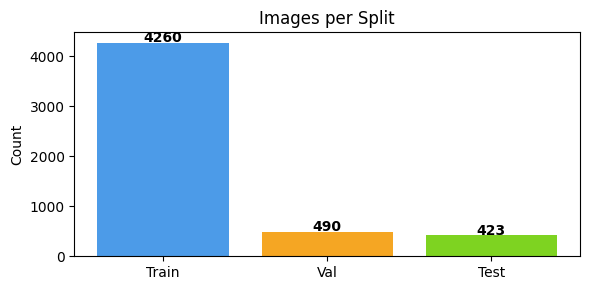

In [7]:
def resolve_val_split(root: Path) -> str:
    if (root / "val" / "images").exists():
        return "val"
    if (root / "valid" / "images").exists():
        return "valid"
    return "val"

def count_split(split):
    img_dir = Path(MERGED_DIR) / split / "images"
    if not img_dir.exists():
        return 0
    return len(list(img_dir.glob("*.jpg"))) + len(list(img_dir.glob("*.png")))

val_split = resolve_val_split(Path(MERGED_DIR))

train_n = count_split("train")
val_n   = count_split(val_split)
test_n  = count_split("test")
total   = train_n + val_n + test_n

print("Merged Dataset Summary")
print("-" * 35)
print(f"  Train : {train_n:>5} images")
print(f"  {val_split.capitalize():<5}: {val_n:>5} images")
print(f"  Test  : {test_n:>5} images")
print("-" * 35)
print(f"  Total : {total:>5} images")

fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(["Train", val_split.capitalize(), "Test"], [train_n, val_n, test_n],
       color=["#4C9BE8", "#F5A623", "#7ED321"])
ax.set_title("Images per Split")
ax.set_ylabel("Count")
for i, v in enumerate([train_n, val_n, test_n]):
    ax.text(i, v + 10, str(v), ha="center", fontweight="bold")
plt.tight_layout()
plt.show()

## Write `data.yaml`

In [8]:
def write_yaml():
    root = Path(MERGED_DIR)
    val_split = "val" if (root / "val" / "images").exists() else "valid"
    config = {
        "path": MERGED_DIR,
        "train": "train/images",
        "val": f"{val_split}/images",
        "test": "test/images",
        "nc": 1,
        "names": ["fracture"]
    }
    yaml_path = os.path.join(MERGED_DIR, "data.yaml")
    with open(yaml_path, "w") as f:
        yaml.dump(config, f, default_flow_style=False, sort_keys=False)
    print(f"data.yaml written to:\n   {yaml_path}")
    print("\nContents:")
    print("-" * 30)
    with open(yaml_path) as f:
        print(f.read())
    return yaml_path

YAML_PATH = write_yaml()

data.yaml written to:
   /workspace/Merged_Fracture/data.yaml

Contents:
------------------------------
path: /workspace/Merged_Fracture
train: train/images
val: val/images
test: test/images
nc: 1
names:
- fracture



## Train YOLO26 (RTX 5090 High-Resolution Profile)

Key decisions:
- **`yolo26n.pt`** — pretrained nano weights (COCO).
- **High resolution (`TRAIN_IMGSZ=1536`)** for finer fracture localization.
- **Auto batch (`BATCH_SIZE=-1`)** to maximize 5090 VRAM usage safely.
- **Mixed precision (`AMP`)** for faster training with high-resolution inputs.
- **HSV hue/saturation = 0** — X-rays are grayscale.

In [ ]:
model = YOLO("/workspace/runs/detect/fracture_yolo26-32/weights/last.pt")  # downloads pretrained weights automatically

results = model.train(
    resume=True,
    data=YAML_PATH,
    epochs=EPOCHS,
    imgsz=TRAIN_IMGSZ,
    batch=BATCH_SIZE,
    project=PROJECT_DIR,
    name=RUN_NAME,
    device=DEVICE,
    workers=NUM_WORKERS,
    amp=USE_AMP,
    cache=CACHE_MODE,
    optimizer="AdamW",

    # ── Augmentation tuned for X-ray images ──────────────────
    hsv_h=0.0,                # disable hue shift (grayscale images)
    hsv_s=0.0,                # disable saturation shift
    hsv_v=0.15,                # slight brightness variation
    flipud=0.2,               # slightly lighter augmentation for speed
    fliplr=0.5,
    degrees=DEGREES,
    mosaic=MOSAIC,
    close_mosaic=CLOSE_MOSAIC,
    augment=True,
    multi_scale=USE_MULTI_SCALE,

    # ── Training stability ────────────────────────────────────
    patience=PATIENCE,
    cos_lr=True,
    warmup_epochs=2,
    deterministic=False,
    plots=PLOTS,
 )

RUN_DIR = Path(getattr(results, "save_dir", Path(PROJECT_DIR) / RUN_NAME))
BEST_WEIGHTS = str(RUN_DIR / "weights" / "best.pt")
RESULTS_CSV = RUN_DIR / "results.csv"

print("\nTraining complete")
print(f"Run directory: {RUN_DIR}")
print(f"Best weights:  {BEST_WEIGHTS}")
print(f"Results CSV:   {RESULTS_CSV}")

def _safe_float(value):
    try:
        return float(value)
    except (TypeError, ValueError):
        return np.nan

if RESULTS_CSV.exists():
    with open(RESULTS_CSV, newline="") as f:
        rows = list(csv.DictReader(f))

    if rows:
        epochs = [int(_safe_float(r.get("epoch", i))) for i, r in enumerate(rows)]

        def _pick_key(candidates):
            for key in candidates:
                if key in rows[0]:
                    return key
            return None

        map50_key = _pick_key(["metrics/mAP50(B)", "metrics/mAP50"] )
        map_key = _pick_key(["metrics/mAP50-95(B)", "metrics/mAP50-95"] )
        prec_key = _pick_key(["metrics/precision(B)", "metrics/precision"] )
        rec_key = _pick_key(["metrics/recall(B)", "metrics/recall"] )

        def _series(key):
            return np.array([_safe_float(r.get(key, np.nan)) for r in rows], dtype=float)

        loss_specs = [
            ("train/box_loss", "Train Box", "#1f77b4"),
            ("val/box_loss", "Val Box", "#17becf"),
            ("train/cls_loss", "Train Cls", "#2ca02c"),
            ("val/cls_loss", "Val Cls", "#98df8a"),
            ("train/dfl_loss", "Train DFL", "#ff7f0e"),
            ("val/dfl_loss", "Val DFL", "#ffbb78"),
        ]

        metric_specs = [
            (map50_key, "mAP@50", "#d62728"),
            (map_key, "mAP@50-95", "#9467bd"),
            (prec_key, "Precision", "#8c564b"),
            (rec_key, "Recall", "#e377c2"),
        ]

        fig, axes = plt.subplots(1, 2, figsize=(15, 5))

        for key, label, color in loss_specs:
            if key in rows[0]:
                y = _series(key)
                if np.isfinite(y).any():
                    axes[0].plot(epochs, y, label=label, color=color, linewidth=2)

        axes[0].set_title("Training and Validation Loss Curves")
        axes[0].set_xlabel("Epoch")
        axes[0].set_ylabel("Loss")
        axes[0].grid(alpha=0.25)
        axes[0].legend()

        for key, label, color in metric_specs:
            if key is not None:
                y = _series(key)
                if np.isfinite(y).any():
                    axes[1].plot(epochs, y, label=label, color=color, linewidth=2)

        axes[1].set_title("Validation Metric Curves")
        axes[1].set_xlabel("Epoch")
        axes[1].set_ylabel("Score")
        axes[1].set_ylim(0, 1)
        axes[1].grid(alpha=0.25)
        axes[1].legend()

        plt.tight_layout()
        plt.show()

        if map50_key is not None:
            map50_vals = _series(map50_key)
            if np.isfinite(map50_vals).any():
                best_idx = int(np.nanargmax(map50_vals))
                best_epoch = epochs[best_idx]

                def _metric_at(key):
                    if key is None:
                        return np.nan
                    return _series(key)[best_idx]

                print("\nBest Epoch Summary")
                print("-" * 40)
                print(f"  Best epoch     : {best_epoch}")
                print(f"  mAP@50         : {_metric_at(map50_key):.4f}")
                if map_key is not None:
                    print(f"  mAP@50-95      : {_metric_at(map_key):.4f}")
                if prec_key is not None:
                    print(f"  Precision      : {_metric_at(prec_key):.4f}")
                if rec_key is not None:
                    print(f"  Recall         : {_metric_at(rec_key):.4f}")

        final_epoch = epochs[-1] if epochs else "N/A"
        print("\nTraining Run Summary")
        print("-" * 40)
        print(f"  Epochs logged  : {len(epochs)}")
        print(f"  Last epoch     : {final_epoch}")
else:
    print("results.csv not found; run training first.")

WARNING ⚠️ model '/workspace/runs/detect/fracture_yolo26-32/weights/last.pt' is not a resumable training checkpoint (missing epoch/optimizer state). Use 'resume' only to continue incomplete training. Starting new training instead.
Ultralytics 8.4.41 🚀 Python-3.12.13 torch-2.11.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5090, 32109MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=True, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=ram, cfg=None, classes=None, close_mosaic=15, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/workspace/Merged_Fracture/data.yaml, degrees=10, deterministic=False, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=140, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.2, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.0, hsv_s=0.0, hsv_v=0.15, imgsz=1024, int8=False, iou=0.7, keras=False, kobj=1.0, line_width

## Evaluate on Test Set

In [ ]:
if not Path(BEST_WEIGHTS).exists():
    raise FileNotFoundError(f"Best weights not found at: {BEST_WEIGHTS}")

eval_model = YOLO(BEST_WEIGHTS)

metrics = eval_model.val(
    data=YAML_PATH,
    split="test",
    imgsz=INFER_IMGSZ,
    conf=CONF_THRESHOLD,
    device=DEVICE,
    half=True,
 )

print("\nTest Set Evaluation Results")
print("-" * 40)
print(f"  mAP@50       : {metrics.box.map50:.4f}")
print(f"  mAP@50-95    : {metrics.box.map:.4f}")
print(f"  Precision    : {metrics.box.mp:.4f}")
print(f"  Recall       : {metrics.box.mr:.4f}")

## Inference on a Single X-Ray Image

Change `TEST_IMAGE_PATH` to any X-ray image you want to test on.

In [ ]:
# Change this to your test image
TEST_IMAGE_PATH = r"test.jpg"

infer_model = YOLO(BEST_WEIGHTS)

results = infer_model.predict(
    source=TEST_IMAGE_PATH,
    conf=CONF_THRESHOLD if "CONF_THRESHOLD" in globals() else 0.25,
    imgsz=INFER_IMGSZ,
    device=DEVICE,
    half=True,
    save=True,
    save_txt=True,
    project=PROJECT_DIR,
    name="inference",
)

# ── Visualize inline ─────────────────────────────────────────
img_bgr = cv2.imread(TEST_IMAGE_PATH)
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

fig, ax = plt.subplots(1, 1, figsize=(10, 8))
ax.imshow(img_rgb, cmap="gray")

detections = []
for r in results:
    for box in r.boxes:
        x1, y1, x2, y2 = box.xyxy[0].tolist()
        conf = float(box.conf)

        rect = patches.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            linewidth=2, edgecolor="#00FF88", facecolor="none"
        )
        ax.add_patch(rect)
        ax.text(x1, y1 - 5, f"Fracture {conf:.2f}",
                color="#00FF88", fontsize=11, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.2", facecolor="black", alpha=0.5))

        detections.append({
            "confidence": conf,
            "bbox_xyxy": [x1, y1, x2, y2],
            "bbox_xywhn": box.xywhn[0].tolist(),
        })

ax.set_title(f"Fracture Detection — {len(detections)} detection(s) found", fontsize=13)
ax.axis("off")
plt.tight_layout()
plt.show()

print("\nStructured output (for LLM module):")
for i, d in enumerate(detections):
    print(f"  Detection {i+1}: conf={d['confidence']:.3f}  bbox={[round(v,1) for v in d['bbox_xyxy']]}")

## Batch Inference on a Folder of X-Rays

In [ ]:
# Use only MERGED_DIR split folders: train / val / test
SPLIT = "test"  # change to "train" or "val" if needed
if SPLIT not in {"train", "val", "test"}:
    raise ValueError("SPLIT must be one of: train, val, test")

INFERENCE_FOLDER = Path(MERGED_DIR) / SPLIT / "images"
if not INFERENCE_FOLDER.exists():
    raise FileNotFoundError(f"Inference folder not found: {INFERENCE_FOLDER}")

infer_model = YOLO(BEST_WEIGHTS)

batch_results = infer_model.predict(
    source=str(INFERENCE_FOLDER),
    conf=CONF_THRESHOLD if "CONF_THRESHOLD" in globals() else 0.25,
    imgsz=INFER_IMGSZ,
    device=DEVICE,
    half=True,
    save=True,
    project=PROJECT_DIR,
    name=f"batch_inference_{SPLIT}",
    stream=True,
)

all_detections = {}
save_dir = None
for r in batch_results:
    save_dir = Path(r.save_dir)
    fname = Path(r.path).name
    boxes = []
    for box in r.boxes:
        boxes.append({
            "confidence": float(box.conf),
            "bbox_xyxy": box.xyxy[0].tolist(),
            "bbox_xywhn": box.xywhn[0].tolist(),
        })
    all_detections[fname] = boxes
    status = f"{len(boxes)} fracture(s)" if boxes else "No fracture detected"
    print(f"  {fname:<40} {status}")

image_count = len(all_detections)
images_with_detections = sum(1 for boxes in all_detections.values() if len(boxes) > 0)
det_counts = [len(boxes) for boxes in all_detections.values()]
all_confidences = [b["confidence"] for boxes in all_detections.values() for b in boxes]

print(f"\nBatch inference complete for '{SPLIT}'.")
print("Batch Summary")
print("-" * 40)
print(f"  Images processed      : {image_count}")
print(f"  Images with fracture  : {images_with_detections}")
print(f"  Total detections      : {sum(det_counts)}")
if all_confidences:
    print(f"  Mean confidence       : {np.mean(all_confidences):.3f}")
    print(f"  Max confidence        : {np.max(all_confidences):.3f}")

print(f"Results saved to {save_dir if save_dir else (Path(PROJECT_DIR) / f'batch_inference_{SPLIT}')}")

if image_count > 0:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    max_det = max(det_counts) if det_counts else 0
    bins = np.arange(0, max_det + 2) - 0.5
    axes[0].hist(det_counts, bins=bins, color="#4C9BE8", edgecolor="white")
    axes[0].set_title("Detections per Image")
    axes[0].set_xlabel("Number of detections")
    axes[0].set_ylabel("Image count")
    axes[0].grid(axis="y", alpha=0.25)

    if all_confidences:
        axes[1].hist(all_confidences, bins=10, color="#F5A623", edgecolor="white")
        axes[1].set_xlim(0, 1)
        axes[1].set_title("Confidence Distribution")
        axes[1].set_xlabel("Confidence")
        axes[1].set_ylabel("Detection count")
        axes[1].grid(axis="y", alpha=0.25)
    else:
        axes[1].text(0.5, 0.5, "No detections found", ha="center", va="center", fontsize=12)
        axes[1].axis("off")

    plt.tight_layout()
    plt.show()

if save_dir and save_dir.exists():
    preview_images = sorted(list(save_dir.glob("*.jpg")) + list(save_dir.glob("*.png")))[:6]

    if preview_images:
        cols = 3
        rows = int(np.ceil(len(preview_images) / cols))
        fig, axes = plt.subplots(rows, cols, figsize=(15, 4 * rows))
        axes = np.array(axes).reshape(-1)

        for i, img_path in enumerate(preview_images):
            img_bgr = cv2.imread(str(img_path))
            if img_bgr is None:
                axes[i].axis("off")
                continue
            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
            axes[i].imshow(img_rgb)
            axes[i].set_title(img_path.name, fontsize=10)
            axes[i].axis("off")

        for j in range(len(preview_images), len(axes)):
            axes[j].axis("off")

        plt.suptitle(f"Sample Predictions ({SPLIT} split)", fontsize=14, y=1.01)
        plt.tight_layout()
        plt.show()

## Export Model for Deployment

Export to ONNX or TensorRT for production use in the pipeline.

In [ ]:
export_model = YOLO(BEST_WEIGHTS)

# Choose your export format:
# 'onnx'        -> universal, works anywhere
# 'torchscript' -> PyTorch deployment
# 'tflite'      -> mobile / edge devices
# 'engine'      -> TensorRT (NVIDIA GPU, fastest inference)

exported_path = export_model.export(
    format="onnx",
    imgsz=INFER_IMGSZ,
    dynamic=True,
    simplify=True,
)

print(f"\nModel exported to: {exported_path}")
print("Use this file in your production pipeline or LLM integration module.")